# Import

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import sklearn
sklearn.set_config(transform_output="pandas") # Forces all transformers to output DataFrames!

# Data Loading & Splitting
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, OrdinalEncoder

# Pipelines and Transformers
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

# Modeling & Evaluation
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score , mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

import seaborn as sns

import matplotlib.pyplot as plt

# Merging and creating new columns

In [2]:
product_df = pd.read_csv('olist_products_dataset.csv')

product_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [3]:
product_df.shape

(32951, 9)

In [4]:
product_df.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [5]:
product_df['product_volume_L'] = (product_df['product_length_cm']*product_df['product_height_cm']*product_df['product_width_cm'])/1000

In [6]:
product_df['product_volume_L'].head()

0     2.240
1    10.800
2     2.430
3     2.704
4     4.420
Name: product_volume_L, dtype: float64

In [7]:
items_df = pd.read_csv('olist_order_items_dataset.csv')

items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
items_df.shape

(112650, 7)

In [9]:
items_df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [10]:
#items_df['order_total_fv'] = items_df.groupby('order_id')['freight_value'].transform('sum')

In [11]:
items_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
50693,73445fb704124d3a8fd5b74bf0e65e28,1,bd7cab8de4d7943286634023cc06f8ff,855668e0971d4dfd7bef1b6a4133b41b,2018-05-17 16:35:23,225.00,66.43
36644,53299baecd9869c74d5c439dc4078eec,1,a5ae8400fc9fcacd4af585a57bbf264a,66922902710d126a0e7d26b0e3805106,2018-02-09 14:55:32,105.00,22.60
60262,895764a4b54b7193c02aa784fabbcaeb,4,00250175f79f584c14ab5cecd80553cd,b499c00f28f4b7069ff6550af8c1348a,2018-02-22 07:07:08,79.99,9.12
26826,3d062cd73698941c34fd1917e8f39482,3,4673b61bd1649eb349682ceb2449e34b,822166ed1e47908f7cfb49946d03c726,2018-02-19 19:07:32,7.99,12.35
98152,dea1d0da023a5aaf8113087fb08ce6c3,1,eab1b8d063b0a7e6a728e68b09a93bfa,d5b9a084373da994a6e37f732169a853,2018-01-26 13:44:32,120.00,16.47


In [12]:
items_df.shape

(112650, 7)

In [13]:
merged_df = items_df.merge(product_df, on='product_id', how='left')

In [14]:
merged_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_L
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0,3.528
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0,60.000
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0,14.157
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0,2.400
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0,42.000


In [15]:
merged_df.shape

(112650, 16)

In [16]:
merged_df['order_total_fv'] = items_df.groupby('order_id')['freight_value'].transform('sum')

In [17]:
merged_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_volume_L,order_total_fv
57154,8216863fd456be73595ea9fa23901d1a,1,5acfd4d25279c8414a02e70a92743c34,918717417d88a9f9ae9735567e6c7682,2018-03-05 22:28:25,10.0,7.78,esporte_lazer,54.0,470.0,3.0,100.0,18.0,14.0,16.0,4.032,7.78
96164,da2b50d5837f2e4ffffe075865ca8b98,1,c23687a012b702cc7d231d3b07deb6e2,a416b6a846a11724393025641d4edd5e,2017-12-26 09:59:41,69.3,17.74,beleza_saude,41.0,1632.0,1.0,1600.0,25.0,16.0,18.0,7.200,17.74
349,00d5fac7792747fba4b528f23930bebd,1,616042729c11849827291496b18e9ec5,6b243f80ed07b10f0e8aa0f21a205f3c,2018-03-12 11:55:39,64.9,15.33,esporte_lazer,45.0,891.0,1.0,300.0,16.0,16.0,16.0,4.096,15.33
24219,372fc04e6d43eb870979226848fa93a1,1,f25bbb88c1a219c21b1af6b99895b960,aaed1309374718fdd995ee4c58c9dfcd,2017-09-28 02:25:22,65.9,27.00,esporte_lazer,42.0,231.0,4.0,550.0,35.0,10.0,20.0,7.000,27.00
81208,b890678ef6e89550a3a5bc432c3ce744,1,205eda573c0d52a57b83bc9332947b8e,6b9b80d53ba3676eafe60268a810b5a1,2017-09-01 20:50:20,79.9,16.32,esporte_lazer,30.0,643.0,8.0,700.0,30.0,36.0,20.0,21.600,16.32


In [18]:
days_df = pd.read_csv('delivered_orders_with_actual_days.csv')

days_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,actual_delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8,9.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9,10.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13,14.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2,3.0


In [19]:
days_df.shape

(96470, 10)

In [20]:
days_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delivery_days', 'actual_delivery_days'],
      dtype='str')

In [21]:
combined_df = merged_df.merge(days_df, on='order_id', how='left')

In [22]:
combined_df.shape

(112650, 26)

In [23]:
combined_df['N_items'] = combined_df.groupby('order_id')['order_item_id'].transform('count')

In [24]:
combined_df['order_weight'] = combined_df.groupby('order_id')['product_weight_g'].transform('sum')

In [25]:
combined_df['order_volume_L'] = combined_df.groupby('order_id')['product_volume_L'].transform('sum')

In [26]:
combined_df['order_categories'] = (
    combined_df.groupby('order_id')['product_category_name']
    .transform(lambda x: ', '.join(x.dropna().astype(str)))
)

In [27]:
combined_df.sample(5)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,...,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,actual_delivery_days,N_items,order_weight,order_volume_L,order_categories
49288,6ffb3f1686bceae3466facf7e02ce3fb,1,c39071c6647a7c3e20d61989ec98c305,20cb7c2fde3e5bf10f0bbe7394e1c6a9,2018-01-29 21:20:27,16.90,15.10,moveis_decoracao,42.0,544.0,...,2018-01-23 21:20:27,2018-01-24 22:55:29,2018-02-14 18:48:51,2018-02-20,21.0,22.0,1,450.0,1.408,moveis_decoracao
39755,5a6a63148f6ab52879bb7c2d7117e366,1,dcecdbaf763f2a027e5b4587ba9ee82b,aba1721a889e04decc910aa13b768ef4,2017-04-11 02:35:36,129.00,16.60,papelaria,44.0,226.0,...,2017-04-05 02:35:36,2017-04-05 11:50:56,2017-04-11 13:23:04,2017-05-02,7.0,7.0,1,200.0,2.352,papelaria
72338,a5002a450fa93774a5c3f26f67889bf9,1,c989db5e9fa3ee241a62cf92a4a27a4b,ececbfcff9804a2d6b40f589df8eef2b,2017-07-14 09:15:19,65.99,11.96,relogios_presentes,49.0,571.0,...,2017-07-10 09:15:19,2017-07-11 18:47:36,2017-07-18 13:04:24,2017-07-28,8.0,9.0,1,200.0,2.100,relogios_presentes
90000,cc780f51d20b4a6024436e6191c844be,1,094e4f4d501b5a6ec753b60a940b069b,14d7985702e72162bbf13b6beb74ab2b,2018-03-22 16:45:33,89.00,19.59,esporte_lazer,47.0,1029.0,...,2018-03-18 17:09:24,2018-03-20 22:58:54,2018-03-29 18:18:10,2018-04-10,11.0,12.0,1,950.0,3.900,esporte_lazer
80136,b64c467f4c3c4270ca94367a26503be2,1,ae39a60d9d830340edf374b7cb0f6e71,a70e9066dbfd10b6b97a3f54a1356762,2017-12-01 18:26:25,429.00,92.34,moveis_decoracao,63.0,1747.0,...,2017-11-20 18:26:25,2017-11-30 18:22:55,2017-12-10 12:09:12,2017-12-20,19.0,20.0,2,60000.0,455.000,"moveis_decoracao, moveis_decoracao"


In [28]:
combined_df.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_volume_L', 'order_total_fv', 'customer_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'delivery_days',
       'actual_delivery_days', 'N_items', 'order_weight', 'order_volume_L',
       'order_categories'],
      dtype='str')

In [29]:
cols_to_keep = [
    'order_id',
    'order_total_fv',
    'order_approved_at',
    'actual_delivery_days',
    'N_items',
    'order_weight',
    'order_volume_L',
    'order_categories'
]

simple_df = combined_df[cols_to_keep].copy()

In [30]:
simple_df

,order_id,order_total_fv,order_approved_at,actual_delivery_days,N_items,order_weight,order_volume_L,order_categories
0,00010242fe8c5a6d1ba2dd792cb16214,13.29,2017-09-13 09:45:35,8.0,1,650.0,3.528,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,19.93,2017-04-26 11:05:13,17.0,1,30000.0,60.000,pet_shop
2,000229ec398224ef6ca0657da4fc703e,17.87,2018-01-14 14:48:30,8.0,1,3050.0,14.157,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,12.79,2018-08-08 10:10:18,7.0,1,200.0,2.400,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,18.14,2017-02-04 14:10:13,26.0,1,3750.0,42.000,ferramentas_jardim
...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,43.41,2018-04-25 04:11:01,16.0,1,10150.0,53.400,utilidades_domesticas
112646,fffcd46ef2263f404302a634eb57f7eb,36.53,2018-07-17 04:31:48,7.0,1,8950.0,44.460,informatica_acessorios
112647,fffce4705a9662cd70adb13d4a31832d,16.95,2017-10-24 17:14:25,4.0,1,967.0,9.576,esporte_lazer
112648,fffe18544ffabc95dfada21779c9644f,8.72,2017-08-15 00:04:32,2.0,1,100.0,8.000,informatica_acessorios


# EDA

In [31]:
simple_df.isnull().sum()

order_id                   0
order_total_fv             0
order_approved_at       2476
actual_delivery_days    2476
N_items                    0
order_weight               0
order_volume_L             0
order_categories           0
dtype: int64

In [32]:
simple_df.dropna(inplace=True)

In [33]:
simple_df.isnull().sum()

order_id                0
order_total_fv          0
order_approved_at       0
actual_delivery_days    0
N_items                 0
order_weight            0
order_volume_L          0
order_categories        0
dtype: int64

In [34]:
simple_df.drop_duplicates(subset=['order_id'], keep='first', inplace=True)

In [35]:
simple_df.shape

(96456, 8)

In [36]:
simple_df.dtypes

order_id                    str
order_total_fv          float64
order_approved_at           str
actual_delivery_days    float64
N_items                   int64
order_weight            float64
order_volume_L          float64
order_categories            str
dtype: object

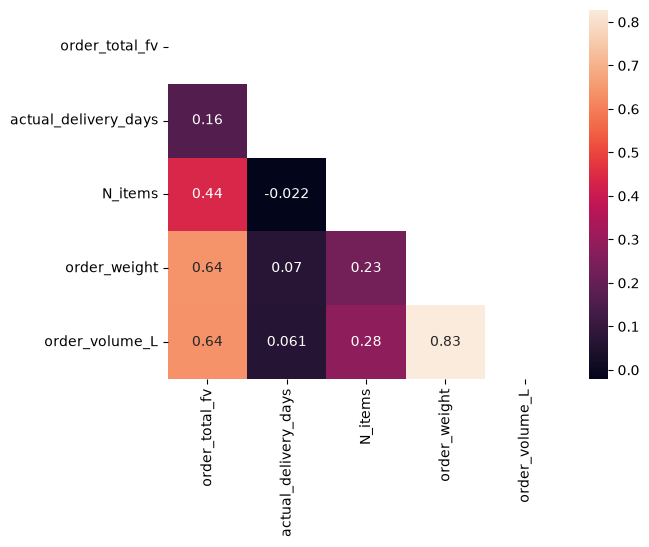

In [37]:
corr_matrix = simple_df.corr(numeric_only=True)

mask = np.tril(np.ones_like(corr_matrix, dtype=bool), k=-1)

sns.heatmap(corr_matrix, mask=~mask, annot=True);

In [38]:
corr_matrix['actual_delivery_days'].abs().sort_values(ascending=False)

actual_delivery_days    1.000000
order_total_fv          0.164175
order_weight            0.070149
order_volume_L          0.061459
N_items                 0.021605
Name: actual_delivery_days, dtype: float64

In [39]:
simple_df.to_csv('simple_df.csv', index=False)